# Lean-15e : Monodromie et groupe fondamental — le cercle épointé à l'œuvre

**Navigation** : [<< Lean-15d Grothendieck en images](Lean-15d-Lean-Grothendieck-Visuel-Python.ipynb) · [Lean-16a Conway >>](Lean-16a-Conway-Man-and-Work.ipynb)

Volet preuve de la fenêtre « 7-bis » greffée dans [Lean-15](Lean-15-Grothendieck-Tribute.ipynb) (distillation #19333-G.beta, issues #21307/#21308). La monodromie y était nommée mais jamais définie ; ce carnet la définit, la calcule et la prouve sur l'exemple le plus simple qui la porte : la couverture `z ↦ z²` du plan complexe épointé. Le module `Grothendieck/Monodromie.lean` du lac `grothendieck_lean` porte les preuves formelles ; ce carnet les met en scène.


## L'idée en une phrase

Quand on fait tourner une boucle autour d'un point singulier, l'objet algébrique transporté le long de la boucle revient **transformé** : cette transformation est la **monodromie**, et elle ne dépend que de la classe d'homotopie de la boucle — c'est-à-dire de son élément dans le **groupe fondamental**.

Le fil conducteur du carnet tient en trois gestes, chacun vérifié deux fois (numériquement, puis dans le noyau de Lean) :

1. **voir** la fibre d'une couverture `p : z ↦ z²` comme un ensemble discret au-dessus d'un point ;
2. **suivre** un point de la fibre le long d'un lacet et constater qu'il ne revient pas forcément sur lui-même ;
3. **formaliser** ce voyage comme une action du groupe fondamental sur la fibre, dont l'ordre mesure le degré de ramification.

À l'arrivée, vous saurez dire pourquoi la racine carrée « ne revient pas » après un tour, pourquoi deux tours suffisent, et ce que le théorème de quasi-unipotence de Grothendieck garantit dans le cadre général.


## Mise en place

Le carnet pilote le lac `grothendieck_lean` (module `Grothendieck.Monodromie`, issue #21308) via les utilitaires de la série. Sous Windows, le lac vit dans la distribution WSL : les utilitaires traduisent chaque commande `lake` et chaque snippet Lean vers le bon chemin sans que le code Python ci-dessous ait à s'en soucier.

**Le décor géométrique.** L'application `p : z ↦ z²` envoie le plan complexe épointé `ℂ* = ℂ \ {0}` sur lui-même. C'est une **couverture de degré 2** : au-dessus de chaque point `w ≠ 0` vivent exactement deux antécédents (les deux racines carrées de `w`), et ces deux points s'échangent continûment quand `w` tourne autour de l'origine. Le point `0` est exclu précisément parce que la structure se casse là : les deux racines de `0` se confondent, c'est un **point de ramification**. Tout ce que le carnet mesure vit dans cet espace épointé.

**La division du travail.** Chaque notion est prise deux fois : d'abord avec NumPy et Matplotlib — pour la *voir* et la manipuler — puis avec un snippet Lean exécuté dans le lac — pour l'énoncer avec les types et les preuves du module. Les cellules numériques précèdent toujours les cellules formelles qui portent le même nom de théorème.


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
from lean_notebook_utils import (
    find_lean_project, get_lean_project_path, run_lake, count_sorry, is_native_platform,
)

proj_win = find_lean_project('grothendieck_lean')
lean_path = get_lean_project_path('grothendieck_lean')
plat = 'natif' if is_native_platform() else 'WSL'
# Chemins absolus non imprimes : ils dependent du poste (classe machine-path,
# EPIC #11044). Les variables restent calculees pour les cellules suivantes ;
# seule la position du lac, relative a la racine du depot, est affichee.
_rel = Path(proj_win).resolve()
_rel = _rel.relative_to(_rel.parents[3]).as_posix()
print(f'Projet Lean (relatif au depot) : {_rel}')
print(f'Plateforme                     : {plat}')


Projet Lean (relatif au depot) : MyIA.AI.Notebooks/SymbolicAI/Lean/grothendieck_lean
Plateforme                     : WSL


Le module doit compiler sans aucun `sorry` avant toute lecture — c'est la vérification que les preuves ci-dessous sont bien dans le noyau.

Cette exigence n'est pas décorative. Un `sorry` dans un théorème cité rendrait chaque `#check` muet sur la question qui compte : « est-ce *prouvé* ? ». Lean distingue soigneusement « le noyau a vérifié ce terme » d'« on a promis de le vérifier plus tard » ; le compteur ci-dessous tranche entre les deux, et la section 5 montrera l'instrument fin (`#print axioms`) qui détecte même le `sorry` hérité *transitivement* d'un lemme auxiliaire qu'on n'a jamais ouvert.


In [2]:
build_timeout_s = 900  # premier build apres cache : long
rc, out, err = run_lake(lean_path, 'build Grothendieck.Monodromie', timeout=build_timeout_s)
print(f'lake build Grothendieck.Monodromie -> rc={rc}')
texte = (out or '') + (err or '')
print(texte[-800:] if texte else '(sortie vide : build deja chaud)')
assert rc == 0, 'le module doit compiler'


lake build Grothendieck.Monodromie -> rc=0
Build completed successfully (1945 jobs).



In [3]:
# Helper : executer un snippet Lean dans le lac (import Grothendieck.Monodromie inclus).
_snip = proj_win / '.lake' / '_snippet_21308.lean'  # .lake est gitignore : jamais commite

# 600 s : mesure po-2028 (lac sur /mnt/c, IO 9p) -- 298,43 s pour ce
# seul jeu de #check ; 300 s expirait sous charge (papermill concurrent).
def lean_snippet(src, timeout=600):
    _snip.write_text('import Grothendieck.Monodromie\n\n' + src, encoding='utf-8')
    rc, out, err = run_lake(lean_path, f'env lean .lake/_snippet_21308.lean', timeout=timeout)
    texte = (out or '') + (err or '')
    print(texte[-3000:] if texte else '(sortie vide)')
    return rc


## 1. La fibre au-dessus de 1 : l'objet transporté

La couverture `p : z ↦ z²` envoie `ℂ*` sur `ℂ*`. La **fibre** de `p` au-dessus de `1` est l'ensemble des antécédents de `1`, autrement dit les solutions de `z² = 1`.

L'image à garder en tête est celle d'une **projection** : la base `ℂ*` est le sol, et au-dessus de chaque point flotte un petit ensemble discret de points — la fibre — comme les étages d'un ascenseur au-dessus de chaque place d'un parking. Une couverture de degré `n` met `n` points dans chaque fibre, et ces `n` points se déplacent **continûment** quand le point de base se déplace : c'est cette continuité qui fera de la fibre un objet transportable le long d'un chemin.

Numériquement, la fibre de `z² = 1` se calcule comme les racines d'un polynôme — ici `z² − 1`, factorisé en `(z−1)(z+1)` :


Fibre de z^2 = 1 : [-1.  1.]


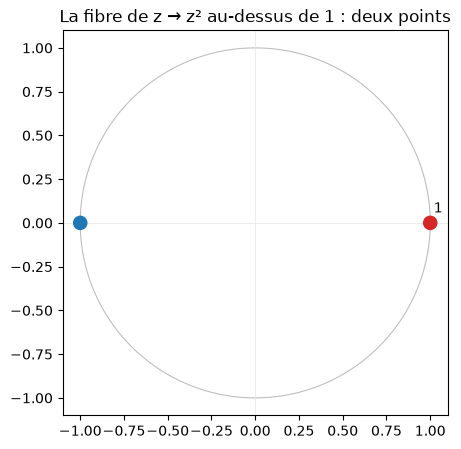

In [4]:
import numpy as np
import matplotlib.pyplot as plt

fibre = np.roots([1, 0, -1])  # racines de z^2 - 1
print('Fibre de z^2 = 1 :', np.round(fibre, 10))

fig, ax = plt.subplots(figsize=(5.6, 5.0))
theta = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(theta), np.sin(theta), color='0.75', lw=0.8)  # cercle unite
ax.scatter(fibre.real, fibre.imag, s=90, color=['#1f77b4', '#d62728'], zorder=3)
ax.annotate('1', (1.02, 0.06)); ax.annotate('-1', (-1.12, 0.06))
ax.set_aspect('equal'); ax.axhline(0, color='0.9', lw=0.5); ax.axvline(0, color='0.9', lw=0.5)
ax.set_title('La fibre de z → z² au-dessus de 1 : deux points')
plt.show()


### Lecture du résultat

Deux points, pas un : la fibre compte le degré de la couverture (ici 2). Le module formalise exactement ce fait.

Ce dénombrement a une conséquence structurelle : il n'existe **aucune fonction continue** `s : ℂ* → ℂ*` telle que `p ∘ s = id` (une *section globale* de la couverture). Une telle section devrait choisir, continûment et partout, l'une des deux racines carrées — impossible, et l'impossibilité est déjà latente dans le fait que la fibre a deux points « indiscernables » vus de la base. C'est précisément en forçant ce choix, puis en le suivant le long d'un lacet, que la section suivante fabrique le phénomène de monodromie.


In [5]:
# La fibre, formellement : exactement {1, -1}, par factorisation (x-1)(x+1) = 0.
rc = lean_snippet(
    '#check @Grothendieck.fiber_sq_one\n'
    '#print axioms Grothendieck.fiber_sq_one\n'
    'example : (-1 : ℂ) ^ 2 = 1 := by norm_num\n'
)
assert rc == 0


Grothendieck.fiber_sq_one : ∀ (x : ℂ), x ^ 2 = 1 ↔ x = 1 ∨ x = -1
'Grothendieck.fiber_sq_one' depends on axioms: [propext, Classical.choice, Quot.sound]



## 2. La boucle générateur et son relèvement

La boucle `γ : t ↦ exp(2πi·t)` fait un tour complet du cercle. Son **relèvement** par la racine carrée part de `1` et suit, à chaque instant, l'unique point de la fibre qui se projette sur `γ(t)` **et** dépend continûment du point de départ choisi.

Le bon réflexe visuel est celui de **l'hélice au-dessus du cercle** : l'exponentielle `s ↦ exp(2πis)` enroule la droite réelle sur le cercle, et le relèvement d'un tour complet est un trajet de longueur 1 — il ne referme la boucle que dans la base, jamais dans la droite. Ici c'est la même mécanique en miniature : le relèvement `t ↦ exp(πit)` fait un *demi*-tour par tour de la base. Sur la figure ci-dessous, la boucle de gauche referme son circuit (elle revient à son point de départ) tandis que son relèvement, à droite, s'arrête à l'antipode. Le point de la fibre a été **transporté** de `1` vers `-1` : la fibre entière a subi une permutation non triviale, et cette permutation est ce qu'on appellera la monodromie de la boucle.

C'est la première apparition du phénomène central : le transport le long d'un chemin **fermé** de la base ne rend pas nécessairement l'objet transporté à son point de départ.


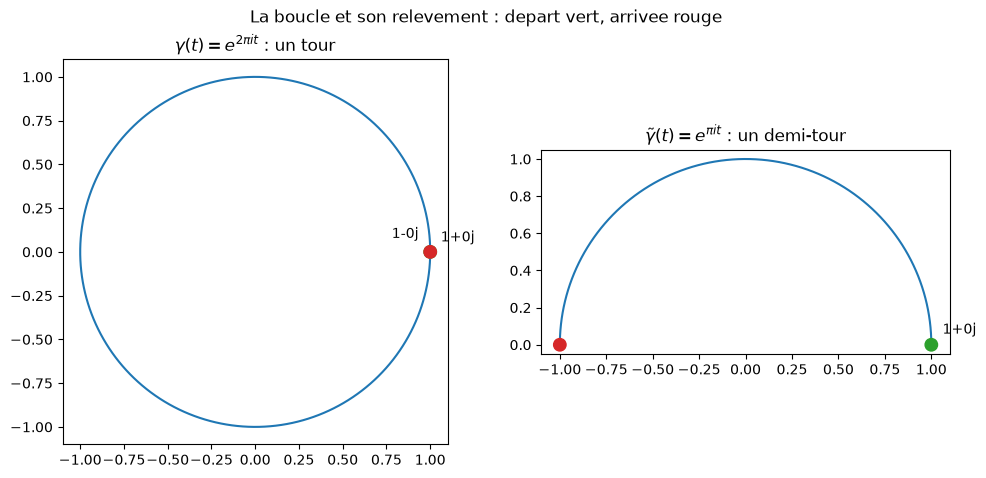

Arrivee du relevement : (-1+0j)


In [6]:
t = np.linspace(0, 1, 200)
gamma = np.exp(2j * np.pi * t)   # la boucle : un tour complet
gamma_tilde = np.exp(1j * np.pi * t)  # le relevement : un demi-tour

fig, (g, d) = plt.subplots(1, 2, figsize=(11.6, 5.0))
for a, z, titre in ((g, gamma, r'$\gamma(t) = e^{2\pi i t}$ : un tour'),
                    (d, gamma_tilde, r'$\tilde\gamma(t) = e^{\pi i t}$ : un demi-tour')):
    a.plot(z.real, z.imag, color='#1f77b4')
    a.scatter([z[0].real, z[-1].real], [z[0].imag, z[-1].imag], s=80, color=['#2ca02c', '#d62728'], zorder=3)
    a.annotate(f'{z[0]:.0f}', (z[0].real + 0.06, z[0].imag + 0.06))
    a.annotate(f'{z[-1]:.0f}', (z[-1].real - 0.22, z[-1].imag + 0.08))
    a.set_aspect('equal'); a.set_title(titre)
plt.suptitle('La boucle et son relevement : depart vert, arrivee rouge')
plt.show()
print('Arrivee du relevement :', np.round(gamma_tilde[-1], 10))


### Lecture du résultat

À gauche, la boucle revient à son départ (c'est un lacet). À droite, le relèvement **part de 1 et arrive en -1** : la racine carrée doit « partager » chaque tour en deux demi-tours, et un seul tour ne suffit pas à refermer.

Deux tours, eux, referment : le relèvement de `t ↦ exp(4πi·t)` est `t ↦ exp(2πi·t)`, un cercle complet — l'exercice 2 le fera mesurer. L'écart entre « un tour » et « deux tours » est exactement l'ordre de la permutation subie par la fibre : c'est le premier nombre que la monodromie met sur la table, et le lien avec l'indice de ramification du point exclu `0` (ici 2) n'est pas une coïncidence — la section suivante l'explique comme une action de groupe.


In [7]:
# Le relevement, formellement : il couvre la boucle et finit en -1.
rc = lean_snippet(
    '#check @Grothendieck.generatorLoop\n'
    '#check @Grothendieck.generatorLift\n'
    '#check @Grothendieck.lift_covers_loop\n'
    '#check @Grothendieck.lift_one\n'
    '#print axioms Grothendieck.lift_one\n'
)
assert rc == 0


Grothendieck.generatorLoop : ℝ → ℂ
Grothendieck.generatorLift : ℝ → ℂ
Grothendieck.lift_covers_loop : ∀ (t : ℝ), Grothendieck.generatorLift t ^ 2 = Grothendieck.generatorLoop t
Grothendieck.lift_one : Grothendieck.generatorLift 1 = -1
'Grothendieck.lift_one' depends on axioms: [propext, Classical.choice, Quot.sound]



## 2 bis. Le groupe fondamental : pourquoi « deux tours ≠ un tour » est une phrase de groupe

Le titre du carnet promet un groupe fondamental ; construisons-le. Deux lacets de `ℂ*` basés en `1` sont **homotopes** si l'un se déforme continûment en l'autre, extrémités fixés. Les classes d'homotopie forment un groupe : le produit est « parcourir le premier lacet, puis le second », l'élément neutre est le lacet constant, l'inverse est le lacet parcouru à l'envers. Ce groupe, noté `π₁(ℂ*, 1)`, est le **groupe fondamental**.

**Le fait central** : `π₁(ℂ*, 1) ≅ ℤ`, engendré par la classe de la boucle `γ : t ↦ exp(2πit)`. Intuitivement, un lacet dans le plan épointé ne peut s'enrouler autour du trou qu'un nombre *entier* de fois — le nombre d'enroulements (`winding number`) est complet : deux lacets homotopes ont le même, et deux lacets de même nombre d'enroulements sont homotopes. Le groupe fondamental du cercle épointé compte des tours, ni plus ni moins.

C'est ici que la monodromie trouve sa vraie définition : suivre la fibre le long d'un lacet ne dépend que de la **classe** du lacet (une déformation continue du chemin déforme continûment le transport). Le transport le long de `γ` donne donc une permutation `σ` de la fibre, le transport le long de `γ∘γ` donne `σ²`, et la permutation associée à un lacet quelconque ne dépend que de son nombre d'enroulements. Autrement dit, la monodromie est un **homomorphisme**

`π₁(ℂ*, 1) ≅ ℤ → Perm(fibre) = S₂`,

et pour `z ↦ z²`, cet homomorphisme envoie le générateur `1` sur la transposition `(1 -1)`. Un tour échange les deux racines, deux tours les rendent : le « deux tours ≠ un tour » mesuré à la section précédente est devenu un énoncé d'algèbre — l'image d'un générateur dans un groupe symétrique. La section suivante calcule exactement cette permutation.


## 3. La monodromie comme action sur la fibre

Transporter la fibre le long de la boucle = permuter ses deux points. Le relèvement envoie `1 ↦ -1`, donc la permutation est la transposition des deux points de la fibre.

Sur la base `(1, -1)` de la fibre, cette transposition s'écrit comme la matrice d'échange — la matrice qui lit « où arrive chaque point ». C'est volontairement le langage le plus concret possible : une **matrice de permutation**, celle qui échange les deux vecteurs de base. La théorie des représentations dirait que la monodromie est une représentation de dimension 2 du groupe fondamental ; pour les besoins du carnet, il suffit de vérifier que cette matrice fait bien ce que le relèvement a montré, et que son carré est l'identité — l'ordre 2 mesuré à la section 2, maintenant écrit dans une matrice :


In [8]:
# La transposition sur la base (1, -1) de la fibre.
M = np.array([[0, 1], [1, 0]])  # e1 (=1) et e2 (=-1) s'echangent
print('M @ (1, 0) =', M @ np.array([1, 0]), ' : le point 1 va en -1')
print('M @ M      ='); print(M @ M, ' : involution, ordre 2')


M @ (1, 0) = [0 1]  : le point 1 va en -1
M @ M      =
[[1 0]
 [0 1]]  : involution, ordre 2


### Lecture du résultat

La matrice échange les deux points et son carré est l'identité. Le module formalise la même action comme fonction `x ↦ -x` préservant la fibre — deux langages (permutation, fonction) pour le même objet, et la correspondance est le pont entre la donnée géométrique (le relèvement de la section 2) et l'énoncé formel.

Notons ce que le langage matriciel ajoute : les **valeurs propres** de l'action deviennent des invariants numériques de la monodromie. Ici `+1` (les objets fixés) et `−1` (les objets échangés) ; pour une couverture de degré `n`, les valeurs propres de la monodromie seront des racines `n`-ièmes de l'unité. Cette remarque prépare la section 4, où les valeurs propres deviennent l'objet du théorème de quasi-unipotence.


In [9]:
rc = lean_snippet(
    '#check @Grothendieck.monodromySq\n'
    '#check @Grothendieck.monodromySq_mem_fiber\n'
    '#check @Grothendieck.monodromySq_sq\n'
    '#check @Grothendieck.monodromy_of_generator\n'
    '#print axioms Grothendieck.monodromy_of_generator\n'
)
assert rc == 0


Grothendieck.monodromySq : ℂ → ℂ
@Grothendieck.monodromySq_mem_fiber : ∀ {x : ℂ}, x ^ 2 = 1 → Grothendieck.monodromySq x ^ 2 = 1
Grothendieck.monodromySq_sq : ∀ (x : ℂ), Grothendieck.monodromySq (Grothendieck.monodromySq x) = x
Grothendieck.monodromy_of_generator : Grothendieck.monodromySq (Grothendieck.generatorLift 0) =
  Grothendieck.generatorLift 1
'Grothendieck.monodromy_of_generator' depends on axioms: [propext, Classical.choice, Quot.sound]



## 4. Quasi-unipotence : le calcul, puis la frontière

Le théorème de quasi-unipotence de Grothendieck (SGA 7, XII) porte sur une famille lisse au-dessus d'un disque épointé : un certain pouvoir de sa monodromie est unipotent. **Mathlib ne le formalise pas** (aucune théorie des familles lisses paramétrées ni de monodromie ℓ-adique), et ce carnet ne le remplace pas : notre monodromie est d'ordre fini (2), cas d'école de l'implication algébrique élémentaire — opérateur d'ordre fini ⇒ valeurs propres racines de l'unité — que le module consigne comme `Prop` documentaire (`finiteOrderEigenvaluesRootsOfUnity`) et que l'exemple vérifie.

Pour situer l'enjeu du théorème réel : dans une famille géométrique, la monodromie n'est **pas** d'ordre fini en général — elle est seulement quasi-unipotente, un mélange d'ordre fini (partie-semi-simple) et d'unipotence (torsion infinitésimale, les valeurs propres s'approchant de 1 comme des racines de l'unité à un facteur près). C'est ce mélange qui rend le théorème profond : il contraint le spectre d'un opérateur qui, a priori, pourrait être quelconque.


In [10]:
print('Valeurs propres de la transposition :', np.linalg.eigvals(M))
print('1 et -1 sont racines de l unites : (1)^2 =', 1**2, ', (-1)^2 =', (-1)**2)
print('M^2 = I : la puissance deux est unipotente (trivialement)')


Valeurs propres de la transposition : [ 1. -1.]
1 et -1 sont racines de l unites : (1)^2 = 1 , (-1)^2 = 1
M^2 = I : la puissance deux est unipotente (trivialement)


### Lecture du résultat

Sur cet exemple : ordre 2, valeurs propres `{1, -1}` toutes racines de l'unité, `M² = I` unipotent (trivialement : identité). Dans cet exemple, M²=I. La conclusion générale visée est seulement qu'une puissance de la monodromie est unipotente ; elle n'impose ni l'ordre 2 ni une puissance égale à l'identité.

En termes de spectre : l'exemple réalise le cas **purement semi-simple** de la quasi-unipotence (valeurs propres racines de l'unité, aucune partie unipotente non triviale). La partie unipotente — celle qui, dans une famille générale, déplace les valeurs propres *près* des racines de l'unité — n'a aucun analogue ici, et c'est précisément ce que « cas d'école » veut dire : une instance où la conclusion est triviale, choisie pour isoler le mécanisme du transport.


In [11]:
rc = lean_snippet(
    '#check @Grothendieck.eigenvalue_neg_one_sq\n'
    '#check @Grothendieck.monodromySq_pow_two_eq_id\n'
    '#check @Grothendieck.finiteOrderEigenvaluesRootsOfUnity\n'
)
assert rc == 0


Grothendieck.eigenvalue_neg_one_sq : (-1) ^ 2 = 1
Grothendieck.monodromySq_pow_two_eq_id : ∀ (x : ℂ), Grothendieck.monodromySq (Grothendieck.monodromySq x) = x
Grothendieck.finiteOrderEigenvaluesRootsOfUnity : Prop



## 5. Intégrité formelle

Le module ne doit contenir aucun `sorry`, et aucun théorème cité ne peut en dépendre transitivement (`sorryAx`).

Les deux instruments du contrôle répondent à deux questions différentes. Le **compteur** `count_sorry` balaie les sources du lac et répond « y a-t-il un `sorry` *écrit* dans `Grothendieck/` ? » — il verrait un trou avoué. Le **`#print axioms`** répond à la question plus fine : « ce théorème *particulier* dépend-il, par l'intermédiaire de quelque lemme auxiliaire que ce soit, de l'axiome `sorryAx` ? » — il verrait un trou **hérité** d'une preuve qu'on n'a jamais ouverte. Un module peut afficher zéro `sorry` écrit tout en citant, depuis un autre module du lac, un théorème lui-même appuyé sur `sorryAx` : seul le second instrument détecte ce cas. La règle de la série exige les deux verts.


In [12]:
n_sorry = count_sorry(str(proj_win), 'Grothendieck/')
print(f'sorry (code reel) dans Grothendieck/ du lac : {n_sorry}')
rc = lean_snippet(
    '#print axioms Grothendieck.fiber_sq_one\n'
    '#print axioms Grothendieck.lift_one\n'
    '#print axioms Grothendieck.monodromy_of_generator\n'
)
assert rc == 0


sorry (code reel) dans Grothendieck/ du lac : 0


'Grothendieck.fiber_sq_one' depends on axioms: [propext, Classical.choice, Quot.sound]
'Grothendieck.lift_one' depends on axioms: [propext, Classical.choice, Quot.sound]
'Grothendieck.monodromy_of_generator' depends on axioms: [propext, Classical.choice, Quot.sound]



### Lecture du résultat

Chaque `#print axioms` ne doit citer que les axiomes standard de Lean (`propext`, `Classical.choice`, `Quot.sound`) — jamais `sorryAx`. La frontière est nette : `finiteOrderEigenvaluesRootsOfUnity` est l'**implication algébrique** élémentaire (opérateur d'ordre fini ⇒ valeurs propres racines de l'unité), consignée et non prouvée ici ; le **théorème géométrique** de SGA 7 — familles lisses sur disque épointé, conclusion unipotente — reste hors Mathlib et hors du module.

Pourquoi ces trois axiomes-là sont acceptés sans discussion : ce sont les axiomes **fondateurs** de Lean lui-même (extensionnalité des propositions, choix classique de ZFC, fonctionnement des quotients), présents dans absolument toute preuve de Mathlib — les interdire reviendrait à réinventer les mathématiques constructives. Le contrat de la série est plus fin : il n'interdit pas ces axiomes, il exige qu'aucun **autre** ne s'invite — `sorryAx` en tête, mais aussi `native_decide`, qui ferait reposer une preuve formelle sur une réduction numérique non vérifiée par le noyau.


## 6. Ce que ce carnet a établi

1. La fibre de `z ↦ z²` au-dessus de 1 est `{1, -1}` (formel : `fiber_sq_one`).
2. Le relèvement de la boucle générateur part de 1 et **arrive en -1** (`lift_one`) — la monodromie visible.
3. La monodromie est la transposition `x ↦ -x`, involution préservant la fibre (`monodromy_of_generator`).
4. Ordre 2, valeur propre racine de l'unité : l'implication algébrique (opérateur d'ordre fini ⇒ racines de l'unité) **vérifiée** sur l'exemple ; le théorème géométrique général (SGA 7) reste hors Mathlib et n'est pas revendiqué.

Relisons le parcours dans le langage de la section 2 bis : tout ce carnet est l'explicitation d'un unique homomorphisme `π₁(ℂ*, 1) ≅ ℤ → S₂`. La fibre (section 1) est l'ensemble où l'action vit ; le relèvement (section 2) calcule l'image du générateur ; l'involution (section 3) est cette image ; l'ordre 2 (section 4) est sa signification arithmétique. Généraliser à `z ↦ zⁿ` remplace `S₂` par le groupe cyclique engendré par un n-cycle — c'est exactement ce que les exercices font mesurer.


## 7. Pour aller plus loin

- **Le pont trèfle** : la même monodromie tord le tore au-dessus de la cubique cuspidale `y² = x³` et fabrique le nœud trèfle — déroulé côté preuves dans [knot_lean](KNOTS/) via la greffe #19356.
- **La fenêtre 7-bis** de [Lean-15](Lean-15-Grothendieck-Tribute.ipynb) situe la monodromie dans le paysage Grothendieck (Weil II, polynôme d'Alexander).
- **SGA 7, XII** : l'énoncé original de la quasi-unipotence, et *Weil II* (Deligne 1980) pour son rôle central.


## 8. Exercices

Trois exercices prolongent le carnet sur la couverture `z ↦ z³` puis sur la lecture générale.

Le fil est volontairement le même que celui du corps du carnet — fibre, relèvement, valeurs propres — mais sur des couvertures de degré plus grand, où les réponses cessent d'être « évidentes » et obligent à vraiment utiliser les définitions. Chaque exercice se résout avec les seules cellules du carnet comme boîte à outils (`np.roots`, `np.linalg.eigvals`, le tracé du relèvement) ; aucun ne demande de nouveau concept.


### Exercice 1 — la fibre de z ↦ z³

Construire la fibre de `z ↦ z³` au-dessus de 1 (trois racines de l'unité), afficher ses points, et dire quelle permutation la monodromie du générateur induit (le relèvement `t ↦ exp(2πi·t/3)` envoie 1 sur `exp(2πi/3)` : un 3-cycle).

**Étapes suggérées.** (1) `np.roots([1, 0, 0, -1])` donne les trois racines de `z³ = 1` — les afficher sur le cercle unité comme à la section 1. (2) Écrire la matrice de permutation `P` du 3-cycle `1 ↦ j ↦ j² ↦ 1` sur la base des trois points. (3) Vérifier `P³ = I` — l'ordre 3 attendu d'un générateur de `S₃` restreint à son support.


In [13]:
# Exercice 1 : fibre de z^3 = 1 et monodromie d'ordre 3
# TODO etudiant : calculer les racines, tracer la fibre, identifier le 3-cycle
# Indice : np.roots([1, 0, 0, -1]) ; le relevement t -> exp(2j*pi*t/3)
resultat = None  # TODO etudiant
print('Exercice a completer')


Exercice a completer


### Exercice 2 — le relèvement de la boucle double

Que devient le relèvement de la boucle parcourue **deux fois** (`t ↦ exp(4πi·t)`), toujours pour `z ↦ z²` ? Partant de 1, où arrive-t-on ? (C'est la question de l'itération de la monodromie — et la raison de son ordre exact.)

**Étapes suggérées.** (1) Tracer `γ₂(t) = exp(4πi·t)` et son relèvement candidat `exp(2πi·t)` côte à côte, comme à la section 2. (2) Lire l'arrivée du relèvement — elle doit être `1`, contrairement au cas d'un seul tour. (3) Relier au langage de la section 2 bis : la boucle double représente `2 ∈ π₁ ≅ ℤ`, son image par la monodromie est `σ² = id` — c'est la définition même de « la monodromie est d'ordre 2 ».


In [14]:
# Exercice 2 : relevement de la boucle double
# TODO etudiant : tracer gamma_2(t) = exp(4j*pi*t) et son relevement exp(2j*pi*t)
# Indice : l'arrivee du relevement repond a la question de l'ordre
resultat = None  # TODO etudiant
print('Exercice a completer')


Exercice a completer


### Exercice 3 — valeurs propres et racines de l'unité

Pour `z ↦ zⁿ` (fibre à n points), la monodromie est un n-cycle — d'ordre fini. Calculer numériquement ses valeurs propres pour n = 3, 4, 5 et vérifier que ce sont toutes des racines de l'unité — la conclusion de l'implication consignée (`finiteOrderEigenvaluesRootsOfUnity`) sur cette famille d'exemples.

**Étapes suggérées.** (1) Construire la matrice du n-cycle (permutation circulaire des vecteurs de base). (2) `np.linalg.eigvals` pour n = 3, 4, 5 ; afficher le module de chaque valeur propre — il doit valoir 1 à précision machine. (3) Comparer au prédit théorique : les valeurs propres d'un n-cycle sont exactement `exp(2πik/n)`, `k = 0..n−1` — l'angle de chaque valeur propre mesurée doit tomber sur un multiple de `2π/n`.


In [15]:
# Exercice 3 : valeurs propres des monodromies d'ordre n = 3, 4, 5
# TODO etudiant : matrice du n-cycle, np.linalg.eigvals, verifier |lambda|^n = 1
# Indice : les valeurs propres d'un n-cycle sont exp(2j*pi*k/n), k = 0..n-1
resultat = None  # TODO etudiant
print('Exercice a completer')


Exercice a completer
